# Simulasi ROI voucher — berapa nilai satu dolar anggaran targeting

Semua estimasi efek sejauh ini menjawab "apakah campaign bekerja". Pertanyaan terakhir operasional: **kalau anggaran voucher terbatas, siapa yang layak diberi** — dan apakah pemilihan itu mengubah ekonomi program. Simulasi ini mengulang peristiwa nyata pada delapan campaign akhir yang tidak pernah dilihat model uplift: pilih audiens per campaign (semua member, top-2/top-4 decile skor uplift, atau top decile RFM sebagai pembanding naif), lalu perkirakan dari data apa adanya — belanja incremental audiens itu dan kupon yang akan terbakar.

Angka margin per kategori tidak ada di data, jadi margin tampil sebagai **parameter eksplisit 15/25/35%**, bukan satu angka. Biaya voucher datang dari `COUPON_DISC` yang benar-benar terobservasi, dalam dua batas atribusi. Dan seluruh hasil tetap **observational — di bawah asumsi unconfoundedness**: simulasi ini menghitung risiko-imbangan *seandainya* efek terestimasi kausal; keputusan produksi tetap memerlukan holdout eksperimen. Konvensi yang mengikat dicatat di decision log.

## Dua batas biaya dan satu konvensi horizon

**Batas ketat**: hanya kupon yang produknya masuk daftar kupon campaign itu, ter-redempt member treated selama window (join transaksi × daftar kupon). **Batas konservatif**: seluruh kupon yang ter-redempt member treated selama window, apa pun asalnya — termasuk kupon campaign lain yang kebetulan bersamaan. Kebenaran ada di antara keduanya: batas ketat nyaris tak berarti untuk campaign TypeB kecil yang daftar kuponnya tipis (biaya mendekati nol membuat rasio meledak), batas konservatif menghukum campaign atas kupon yang bukan miliknya.

Horizon dihitung konsisten dalam window: belanja incremental = uplift mingguan × panjang window × ukuran audiens, dibandingkan dengan biaya total window — rumus margin×belanja−biaya hanya sah kalau keduanya berdurasi sama. Kolom ekonomi fase DiD memakai konvensi mingguan (ATT×n treated atas biaya total window); relasi keduanya eksak: **rasio window = rasio mingguan × panjang window** — diverifikasi 0,0% selisih di kedelapan campaign.

In [1]:
import sys
import time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.features import PROCESSED_DIR
from src.simulate import MARGIN_LEVELS, load_roi_inputs, scenario_core, select_mask, simulate

pd.set_option("display.width", 160)

roi = load_roi_inputs()
print(f"input simulasi: {len(roi):,} baris (household × campaign akhir held-out) | 8 campaign | window {roi['n_weeks_window'].min()}–{roi['n_weeks_window'].max()} minggu")
print(f"biaya terobservasi — ketat ${roi['cost_tight'].sum():,.0f} | semua kupon ${roi['cost_all'].sum():,.0f}")

did = pd.read_parquet(PROCESSED_DIR / "campaign_did_results.parquet").set_index("campaign_id")
rows = []
for cid, g in roi.groupby("campaign_id"):
    core = scenario_core(g.assign(_camp_code=0), select_mask(g, None, None))
    rows.append({
        "campaign": int(cid),
        "minggu": int(g["n_weeks_window"].iloc[0]),
        "per-$1 simulasi (window)": round(core["inc_per_dollar_tight"], 2),
        "per-$1 DiD (mingguan)": round(float(did.loc[cid, "inc_spend_per_dollar"]), 2),
        "per-$1 DiD × minggu": round(float(did.loc[cid, "inc_spend_per_dollar"]) * g["n_weeks_window"].iloc[0], 2),
    })
pd.DataFrame(rows)

input simulasi: 14,090 baris (household × campaign akhir held-out) | 8 campaign | window 5–11 minggu
biaya terobservasi — ketat $2,775 | semua kupon $15,162


,campaign,minggu,per-$1 simulasi (window),per-$1 DiD (mingguan),per-$1 DiD × minggu
0,16,5,165.02,33.00,165.02
1,17,5,78.85,15.77,78.85
2,18,8,20.18,2.52,20.18
3,19,5,87.53,17.51,87.53
4,20,11,903.51,82.14,903.51
5,22,5,168.06,33.61,168.06
6,23,6,179.81,29.97,179.81
7,25,5,118.14,23.63,118.14


Identitas terpenuhi persis — mesin simulasi dan estimasi DiD sepakat, beda hanya durasi pembukuan. Sekarang lima skenario targeting dijalankan pada audiens yang sama, dengan CI cluster-bootstrap per household (1.000 resample; keanggotaan audiens tetap, ketidakpastian outcome dan biaya yang di-bootstrapping).

In [2]:
t0 = time.time()
tbl = simulate(roi, n_bootstrap=1000)
tbl_layak = simulate(roi, n_bootstrap=1000, campaign_set="layak")
both = pd.concat([tbl, tbl_layak], ignore_index=True)
both.to_parquet(PROCESSED_DIR / "roi_scenarios.parquet", index=False)
print(f"simulasi + bootstrap: {time.time()-t0:.0f}s | artefak: roi_scenarios.parquet ({len(both)} baris)")

show = ["scenario", "n_targeted", "uplift_per_member_week", "incr_spend_total",
        "cost_tight", "inc_per_dollar_tight", "inc_per_dollar_tight_ci_low", "inc_per_dollar_tight_ci_high",
        "cost_all", "inc_per_dollar_all", "breakeven_margin_tight"]
tbl[show].round(2)

simulasi + bootstrap: 15s | artefak: roi_scenarios.parquet (10 baris)


,scenario,n_targeted,uplift_per_member_week,incr_spend_total,cost_tight,inc_per_dollar_tight,inc_per_dollar_tight_ci_low,inc_per_dollar_tight_ci_high,cost_all,inc_per_dollar_all,breakeven_margin_tight
0,blanket,14090.0,7.06,626023.51,6927.93,90.36,62.25,121.84,50826.85,12.32,0.01
1,uplift top-2 decile,2822.0,12.47,221609.07,954.41,232.19,124.13,402.03,6985.23,31.73,0.00
2,uplift top-4 decile,5640.0,10.39,368800.85,1991.55,185.18,103.70,309.44,15883.70,23.22,0.01
3,RFM top-2 decile,2822.0,7.19,127815.90,2071.11,61.71,32.45,96.53,13053.75,9.79,0.02
4,RFM top-4 decile,5640.0,8.99,319337.48,3371.68,94.71,67.17,127.05,22370.66,14.27,0.01


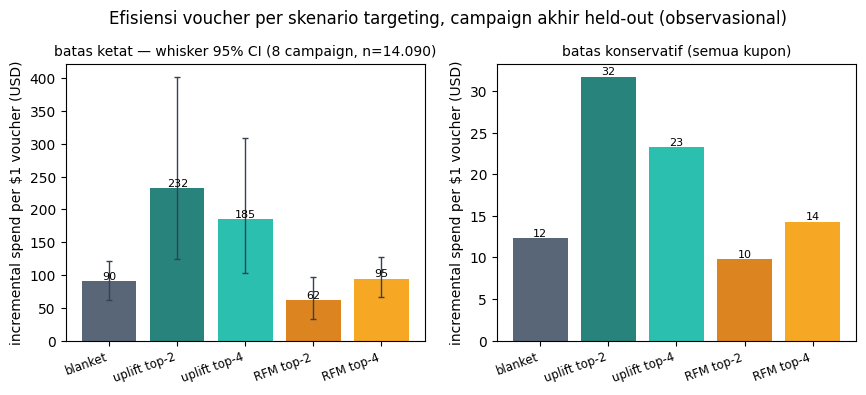

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.6), sharex=True)
labels = ["blanket", "uplift top-2", "uplift top-4", "RFM top-2", "RFM top-4"]
short = {"blanket": "blanket", "uplift top-2 decile": "uplift top-2", "uplift top-4 decile": "uplift top-4",
         "RFM top-2 decile": "RFM top-2", "RFM top-4 decile": "RFM top-4"}
colors = ["#475569", "#0f766e", "#14b8a6", "#d97706", "#f59e0b"]
x = np.arange(len(tbl))
for ax, col, err, title in [
    (axes[0], "inc_per_dollar_tight", "inc_per_dollar_tight_ci_high", "batas ketat (atribusi daftar kupon)"),
    (axes[1], "inc_per_dollar_all", None, "batas konservatif (semua kupon)"),
]:
    vals = tbl[col].to_numpy(float)
    ax.bar(x, vals, color=colors, alpha=0.9)
    if err:
        e = tbl[err].to_numpy(float) - vals
        ax.errorbar(x, vals, yerr=np.vstack([vals - tbl["inc_per_dollar_tight_ci_low"].to_numpy(float), e]),
                    fmt="none", ecolor="#334155", lw=1, capsize=2)
    for xi, v in zip(x, vals):
        ax.annotate(f"{v:,.0f}", (xi, v), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, labels, rotation=20, ha="right", fontsize=8.5)
    ax.set_ylabel("incremental spend per $1 voucher (USD)")
    ax.set_title(title, fontsize=10)
axes[0].set_title(f"batas ketat — whisker 95% CI (8 campaign, n=14.090)", fontsize=10)
fig.suptitle("Efisiensi voucher per skenario targeting, campaign akhir held-out (observasional)", y=1.03)
plt.show()

**Targeting berbasis skor uplift memecahkan masalah anggaran; RFM naif justru membakar kupon.** Pada batas ketat, top-2 decile skor uplift menghasilkan **$232 incremental spend per $1 voucher (95% CI 124–402)** — 2,6× blanket ($90) dan 3,8× RFM top-2 ($62). Urutan yang sama bertahan di batas konservatif (**$31,7 vs $12,3 blanket vs $9,8 RFM**) dan di subset campaign lolos-gate ($517 vs $228 vs $210), jadi kesimpulannya tidak artefak satu batas atribusi. Kenapa RFM kalah dari blanket: audiens high-spend yang ditarget RFM memang paling sering menerima campaign — biaya kupon terobservasinya paling besar ($2.071 vs $954 uplift top-2) sementara belanja incrementalnya lebih kecil ($127,8rb vs $221,6rb). Skor uplift mengarah ke member margin penargetan: responsif terhadap treatment dan murah kuponnya.

Dalam bahasa margin (parameter asumsi, bukan data): pada margin grocery 25% dan batas konservatif — skenario paling hati-hati — top-2 decile memberi **+$6,9 incremental margin per $1 voucher** (blanket +$2,1), dengan titik break-even margin **3,2%** (blanket 8,1%). Voucher membayar dirinya dalam window campaign pada setiap level margin yang diuji, dengan dua syarat yang menyertai setiap angka: efek harus dibaca sebagai estimasi observational, dan CI top-decile lebar (bootstrap antar-household) karena audiensnya seperlima populasi.

In [4]:
# sensitivitas margin × batas: incremental margin per $1 voucher = margin% × per-$1 − 1
sens_rows = []
for r in tbl.itertuples():
    row = {"skenario": r.scenario}
    for m in MARGIN_LEVELS:
        row[f"ketat {int(m*100)}%"] = m * r.inc_per_dollar_tight - 1
        row[f"semua kupon {int(m*100)}%"] = m * r.inc_per_dollar_all - 1
    row["break-even ketat"] = r.breakeven_margin_tight
    row["break-even semua kupon"] = 1 / r.inc_per_dollar_all
    sens_rows.append(row)
sens = pd.DataFrame(sens_rows).set_index("skenario")
print("incremental margin per $1 voucher (USD); negatif = rugi pada level margin itu")
sens.round(2)

incremental margin per $1 voucher (USD); negatif = rugi pada level margin itu


,ketat 15%,semua kupon 15%,ketat 25%,semua kupon 25%,ketat 35%,semua kupon 35%,break-even ketat,break-even semua kupon
skenario,,,,,,,,
blanket,12.55,0.85,21.59,2.08,30.63,3.31,0.01,0.08
uplift top-2 decile,33.83,3.76,57.05,6.93,80.27,10.10,0.00,0.03
uplift top-4 decile,26.78,2.48,45.30,4.80,63.81,7.13,0.01,0.04
RFM top-2 decile,8.26,0.47,14.43,1.45,20.60,2.43,0.02,0.10
RFM top-4 decile,13.21,1.14,22.68,2.57,32.15,4.00,0.01,0.07


In [5]:
# subset identifikasi bersih (5 campaign lolos gate) — angka pembanding
tbl_layak[["scenario", "n_targeted", "inc_per_dollar_tight",
           "inc_per_dollar_tight_ci_low", "inc_per_dollar_tight_ci_high",
           "inc_per_dollar_all", "breakeven_margin_tight"]].round(2)

,scenario,n_targeted,inc_per_dollar_tight,inc_per_dollar_tight_ci_low,inc_per_dollar_tight_ci_high,inc_per_dollar_all,breakeven_margin_tight
0,blanket,8021.0,228.37,144.98,341.65,14.55,0.0
1,uplift top-2 decile,1607.0,516.89,209.92,1320.97,34.04,0.0
2,uplift top-4 decile,3211.0,470.17,194.94,1043.96,25.87,0.0
3,RFM top-2 decile,1607.0,210.18,117.17,326.24,13.69,0.0
4,RFM top-4 decile,3211.0,256.82,167.57,381.40,16.56,0.0


## Batasan pembacaan

- **Observational (label menyertai semua angka).** Simulasi mewarisi asumsi unconfoundedness dari estimasi efek; kalau bias seleksi win-back tersisa, angka margin ikut berubah. Rekomendasi operasional yang benar adalah uji holdout 10%, bukan peluncuran penuh berdasarkan simulasi.
- **Biaya per-targeted diekstrapolasi** dari member treated yang terobservasi — satu-satunya sumber perilaku redemption nyata. Audiens dengan sedikit treated (decile bawah RFM) punya biaya paling tak pasti; decile dengan n < 30 tidak pernah diklaim di fase evaluasi, dan di sini audiensnya berukuran ribuan.
- **Batas ketat meledak untuk campaign TypeB kecil** (mis. campaign 20: $903 per $1 karena daftar kuponnya hanya menyentuh $46 biaya) — itulah mengapa kesimpulan utama dibaca dari urutan yang stabil di **kedua** batas, bukan dari satu rasio.
- CI berasal dari bootstrap antar-household dengan keanggotaan audiens tetap; ketidakpastian pemilihan skor (model itu sendiri) tidak dimasukkan — margin tipis antar skenario tidak boleh dibaca presisi.
- Rasio ini unitless dan berlaku untuk panel ini; untuk transfer ke konteks lain, angka yang dibawa adalah rasionya, bukan dollarnya.